#### メンバー

牧野航大　大島勇希　永井港人

## 分析結果と考察

今回の分析では、被害者の年齢と施錠状況の関係を調べた。

まず、全体の施錠状況を見ると、施錠せずに盗難に遭ったケースは6,879件で全体の68.4％、施錠していたケースは3,175件で31.6％だった。このことから、今回の盗難被害データでは、施錠していなかったケースが多いことが分かった。

次に、年齢別に比較すると、10歳代では施錠せずに盗難に遭った割合が76.4％だった。一方、60～64歳では48.0％、65～69歳では46.2％だった。この結果から、若い年齢層では施錠せずに盗難に遭ったケースの割合が比較的高い傾向が確認できた。

さらに、カイ二乗検定を行った結果、年齢と施錠状況には統計的に有意な関連が認められた。ただし、関連の強さは大きくないため、年齢だけが施錠状況を決めているとは言えない。

以上の結果から、特に10歳代などの若い年齢層に対して、学校での自転車の施錠指導や二重ロックの重要性を伝える活動が有効だと考える。

また、年齢に関係なく、短時間の駐輪であっても必ず施錠する習慣を身につけることが重要である。

In [ ]:

#filename = "bike.csv"
#encoding = "cp932"
#import pandas as pd
#df = pd.read_csv(filename, encoding=encoding)

# 時刻が不明の事件は、0時に変えず別に数える
#hours = {}
##unknown_hours = 0
#for row in incidents:
    #value = row["発生時（始期）"]
    #if value.isdigit():
    #    hour = int(value)
    #    hours[hour] = hours.get(hour, 0) + 1
    #else:
    #    unknown_hours += 1



In [2]:
#データの読み込み・確認
import pandas as pd
import matplotlib.pyplot as plt

# CSVの読み込み
df = pd.read_csv("bike.csv", encoding="cp932")

# データの確認


In [3]:
# 年齢と施錠状況の組み合わせを集計
result = {}

for age, lock in zip(df["被害者の年齢"], df["施錠関係"]):

    # 法人・団体などは除外
    if age == "法人・団体、被害者なし":
        continue

    if age not in result:
        result[age] = {"施錠した": 0, "施錠せず": 0}

    if lock == "施錠した":
        result[age]["施錠した"] += 1
    elif lock == "施錠せず":
        result[age]["施錠せず"] += 1

# 結果を表示
for age, counts in result.items():

    total = counts["施錠した"] + counts["施錠せず"]

    unlocked_rate = counts["施錠せず"] / total * 100
    locked_rate = counts["施錠した"] / total * 100

    print(
        age,
        "被害件数:", total,
        "施錠せず:", round(unlocked_rate, 1), "%",
        "施錠した:", round(locked_rate, 1), "%"
    )

20歳代 被害件数: 2615 施錠せず: 64.9 % 施錠した: 35.1 %
10歳代 被害件数: 4460 施錠せず: 76.4 % 施錠した: 23.6 %
30歳代 被害件数: 952 施錠せず: 63.7 % 施錠した: 36.3 %
40歳代 被害件数: 768 施錠せず: 57.7 % 施錠した: 42.3 %
10歳未満 被害件数: 69 施錠せず: 88.4 % 施錠した: 11.6 %
50歳代 被害件数: 610 施錠せず: 58.0 % 施錠した: 42.0 %
60-64歳 被害件数: 150 施錠せず: 48.0 % 施錠した: 52.0 %
70歳以上 被害件数: 297 施錠せず: 57.6 % 施錠した: 42.4 %
65-69歳 被害件数: 106 施錠せず: 46.2 % 施錠した: 53.8 %


[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 27507 (\N{CJK UNIFIED IDEOGRAPH-6B73}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 20195 (\N{CJK UNIFIED IDEOGRAPH-4EE3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 28288 (\N{CJK UNIFIED IDEOGRAPH-6E80}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 20197 (\N{CJK UNIFIED IDEOGRAPH-4EE5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
[local]\AppData\Local\Temp\ipykernel_10228\3634711731.py:30: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing fro

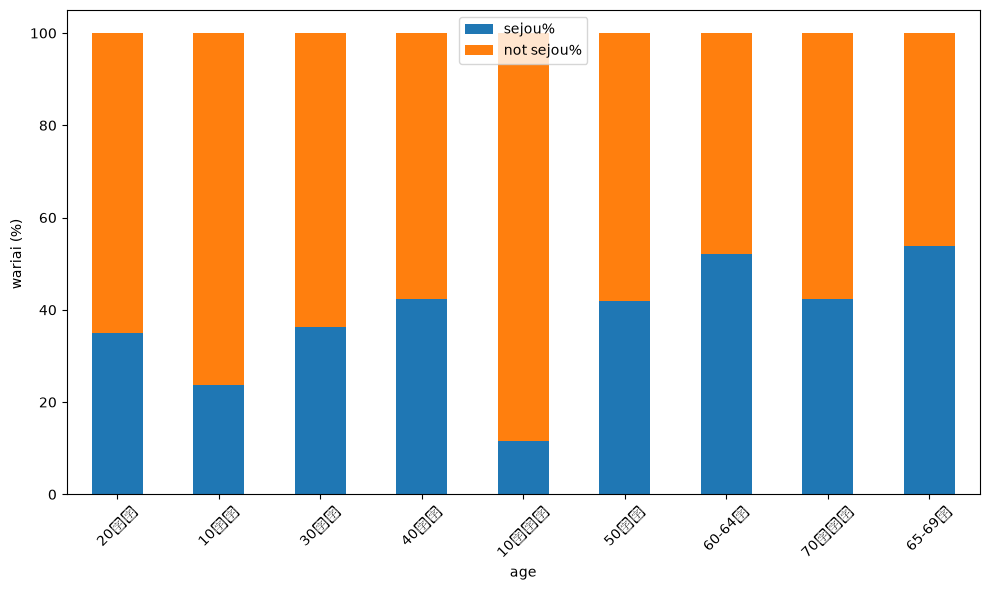

In [7]:
# 集計結果をDataFrameに変換
result_df = pd.DataFrame(result).T

# 割合に変換
result_df["合計"] = (
    result_df["施錠した"] + result_df["施錠せず"]
)

result_df["sejou%"] = (
    result_df["施錠した"] / result_df["合計"] * 100
)

result_df["not sejou%"] = (
    result_df["施錠せず"] / result_df["合計"] * 100
)

# グラフ
result_df[
    ["sejou%", "not sejou%"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("age")
plt.ylabel("wariai (%) ")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:

import pandas as pd
from scipy import stats

df = pd.read_csv("bike.csv", encoding="cp932")

# 法人・団体を除外
mask = df["被害者の年齢"] != "法人・団体、被害者なし"

table = pd.crosstab(
    df.loc[mask, "被害者の年齢"],
    df.loc[mask, "施錠関係"]
)

chi2, p, dof, expected = stats.chi2_contingency(table)

print(table)
print("カイ二乗値:", chi2)
print("p値:", p)
print("自由度:", dof)
print("最小期待度数:", expected.min())

if p < 0.05:
    print("年齢と施錠関係には統計的に有意な関連があります")
else:
    print("年齢と施錠関係には統計的に有意な関連が確認できません")

施錠関係    施錠した  施錠せず
被害者の年齢            
10歳代    1054  3406
10歳未満      8    61
20歳代     917  1698
30歳代     346   606
40歳代     325   443
50歳代     256   354
60-64歳    78    72
65-69歳    57    49
70歳以上    126   171
カイ二乗値: 308.5487136750788
p値: 6.233046408356147e-62
自由度: 8
最小期待度数: 21.793457664306374
年齢と施錠関係には統計的に有意な関連があります
